# Task 2 — Receptive-field ablation (tell-the-time)

Reproduces Table 3 and Figure 3 of the report: how the error of a multi-head clock
CNN depends on the receptive field, at a fixed input resolution and across resolutions.

Runtime: GPU (Runtime -> Change runtime type -> GPU). About 50 minutes end to end.

Expects `A1_data_75.zip` and `A1_data_150.zip` in Google Drive; adjust `DRIVE_DIR` below.

## 1. Setup

In [1]:
import json, time
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
DRIVE_DIR = '/content/drive/MyDrive'      # change if your zips live elsewhere

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.__version__, device)

2.11.0+cu130 cuda


## 2. Data

Same split for both resolutions: `default_rng(42).permutation(18000)`, 80/10/10 in the order train, validation, test. Images are normalised with the mean and standard deviation of the training split.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -o -q "$DRIVE_DIR/A1_data_75.zip"  -d /content/clock75
!unzip -o -q "$DRIVE_DIR/A1_data_150.zip" -d /content/clock150


def make_loaders(folder, batch_train=64, batch_eval=128, seed=SEED):
    X = np.load(f'{folder}/images.npy').astype(np.float32) / 255.0
    y = np.load(f'{folder}/labels.npy')
    X = X[:, None, :, :]                                  # (N, 1, H, W)
    y_min = (y[:, 0] * 60 + y[:, 1]).astype(np.int64)     # minutes since 12:00, 0-719

    idx = np.random.default_rng(seed).permutation(len(X))
    n_tr, n_va = 14400, 1800
    tr, va, te = idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:]

    X_t, y_t = torch.from_numpy(X), torch.from_numpy(y_min)
    mean, std = X_t[tr].mean(), X_t[tr].std()
    X_t = (X_t - mean) / std

    ds = lambda i: TensorDataset(X_t[i], y_t[i])
    loaders = (DataLoader(ds(tr), batch_size=batch_train, shuffle=True),
               DataLoader(ds(va), batch_size=batch_eval,  shuffle=False),
               DataLoader(ds(te), batch_size=batch_eval,  shuffle=False))
    del X, X_t
    return loaders


train75,  val75,  test75  = make_loaders('/content/clock75')
train150, val150, test150 = make_loaders('/content/clock150')
print(len(train150.dataset), len(val150.dataset), len(test150.dataset))

Mounted at /content/drive
14400 1800 1800


## 3. Model

A multi-head CNN: a shared convolutional backbone, then a 256-unit fully connected
layer, then two classification heads (12 hours, 60 minutes).

Each block is `conv 3x3 -> [BatchNorm] -> ReLU -> maxpool 2x2`. Setting `dil > 1`
enlarges the receptive field without changing the number of parameters or the spatial
size of the feature maps, which is what separates the receptive field from the size of
the flatten layer.

In [3]:
class MultiHeadClock(nn.Module):
    def __init__(self, channels=(32, 64, 128), fc=256, img=150, dil=1, bn=False):
        super().__init__()
        layers, c = [], 1
        for ch in channels:
            layers.append(nn.Conv2d(c, ch, 3, padding=dil, dilation=dil))
            if bn:
                layers.append(nn.BatchNorm2d(ch))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            c = ch
        self.features = nn.Sequential(*layers)
        with torch.no_grad():
            self.flat = self.features(torch.zeros(1, 1, img, img)).numel()
        self.shared = nn.Sequential(nn.Flatten(), nn.Linear(self.flat, fc), nn.ReLU())
        self.hour_head = nn.Linear(fc, 12)
        self.min_head  = nn.Linear(fc, 60)

    def forward(self, x):
        z = self.shared(self.features(x))
        return self.hour_head(z), self.min_head(z)


def receptive_field(n_blocks, dil=1):
    """Theoretical RF of the last conv layer, for n blocks of conv3x3 + maxpool2."""
    r, j = 1, 1
    for _ in range(n_blocks):
        r += 2 * dil * j      # 3x3 conv with dilation dil
        r += j                # 2x2 max pool
        j *= 2
    return r


print({n: receptive_field(n) for n in (3, 4, 5)}, '| dilated 3 blocks:', receptive_field(3, 3))

{3: 22, 4: 46, 5: 94} | dilated 3 blocks: 50


## 4. Training and evaluation

The metric is the common-sense error: with `d = (prediction - target) mod 720`, the
error is `min(d, 720 - d)` in minutes, averaged over the set. The loss is the sum of
the cross-entropies of the two heads.

In [4]:
def common_sense_error(pred_min, true_min):
    d = np.abs(np.asarray(pred_min) - np.asarray(true_min)) % 720
    return np.minimum(d, 720 - d).mean()


mh_target = lambda y: torch.stack([y // 60, y % 60], dim=1)
mh_to_min = lambda out: (out[0].argmax(1) * 60 + out[1].argmax(1)).cpu().numpy()


def mh_criterion(out, target, alpha=1.0):
    h_out, m_out = out
    return (nn.functional.cross_entropy(h_out, target[:, 0])
            + alpha * nn.functional.cross_entropy(m_out, target[:, 1]))


def train_one_epoch(model, loader, optimizer):
    model.train()
    running = 0.0
    for images, y in loader:
        images, targets = images.to(device), mh_target(y).to(device)
        optimizer.zero_grad()
        loss = mh_criterion(model(images), targets)
        loss.backward()
        optimizer.step()
        running += loss.item() * images.size(0)
    return running / len(loader.dataset)


def evaluate(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for images, t in loader:
            preds.append(mh_to_min(model(images.to(device))))
            trues.append(t.numpy())
    return common_sense_error(np.concatenate(preds), np.concatenate(trues))


def run(tag, train_dl, val_dl, n_blocks, img, dil=1, bn=False,
        lr=3e-4, epochs=30, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    channels = (32, 64, 128, 256, 256)[:n_blocks]
    model = MultiHeadClock(channels=channels, img=img, dil=dil, bn=bn).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    hist = {'train_loss': [], 'val_cse': []}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_dl, optimizer)
        va = evaluate(model, val_dl)
        hist['train_loss'].append(tr)
        hist['val_cse'].append(va)
        if verbose:
            print(f'[{tag}] epoch {epoch:2d}: train loss {tr:.4f} | val CSE {va:.1f} min')

    return {'tag': tag, 'blocks': n_blocks, 'input': img, 'dilation': dil, 'batchnorm': bn,
            'rf': receptive_field(n_blocks, dil), 'flatten': model.flat,
            'best_val_cse': min(hist['val_cse']),
            'best_epoch': int(np.argmin(hist['val_cse'])) + 1,
            'final_val_cse': hist['val_cse'][-1],
            'time_s': round(time.time() - t0, 1),
            'history': hist, 'model': model}

## 5. Experiments

The six configurations of Table 3, in the order they appear there. About 50 minutes in total on a T4.

In [5]:
configs = [
    dict(tag='3blocks_75',        train_dl=train75,  val_dl=val75,  n_blocks=3, img=75),
    dict(tag='3blocks_150',       train_dl=train150, val_dl=val150, n_blocks=3, img=150),
    dict(tag='3blocks_dil3_150',  train_dl=train150, val_dl=val150, n_blocks=3, img=150, dil=3),
    dict(tag='4blocks_150',       train_dl=train150, val_dl=val150, n_blocks=4, img=150),
    dict(tag='5blocks_150',       train_dl=train150, val_dl=val150, n_blocks=5, img=150),
    dict(tag='5blocks_bn_150',    train_dl=train150, val_dl=val150, n_blocks=5, img=150, bn=True),
]

results = [run(**cfg) for cfg in configs]

[3blocks_75] epoch  1: train loss 6.5788 | val CSE 154.1 min
[3blocks_75] epoch  2: train loss 6.1854 | val CSE 106.9 min
[3blocks_75] epoch  3: train loss 5.3975 | val CSE 82.9 min
[3blocks_75] epoch  4: train loss 4.6976 | val CSE 64.4 min
[3blocks_75] epoch  5: train loss 4.0560 | val CSE 53.4 min
[3blocks_75] epoch  6: train loss 3.5615 | val CSE 46.4 min
[3blocks_75] epoch  7: train loss 3.1571 | val CSE 38.0 min
[3blocks_75] epoch  8: train loss 2.8315 | val CSE 35.5 min
[3blocks_75] epoch  9: train loss 2.5490 | val CSE 33.4 min
[3blocks_75] epoch 10: train loss 2.2950 | val CSE 29.4 min
[3blocks_75] epoch 11: train loss 2.0708 | val CSE 29.3 min
[3blocks_75] epoch 12: train loss 1.8579 | val CSE 27.2 min
[3blocks_75] epoch 13: train loss 1.6842 | val CSE 27.7 min
[3blocks_75] epoch 14: train loss 1.5196 | val CSE 27.7 min
[3blocks_75] epoch 15: train loss 1.3588 | val CSE 21.9 min
[3blocks_75] epoch 16: train loss 1.2100 | val CSE 25.4 min
[3blocks_75] epoch 17: train loss 1.08

## 6. Results table

This reproduces Table 3 of the report.

In [6]:
df = pd.DataFrame([{
    'Configuration': r['tag'],
    'Input': f"{r['input']}x{r['input']}",
    'RF (px)': r['rf'],
    'RF / width': f"{r['rf'] / r['input']:.0%}",
    'Flatten': f"{r['flatten']:,}",
    'Val CSE (min)': round(r['best_val_cse'], 1),
    'Best epoch': r['best_epoch'],
    'Time (s)': r['time_s'],
} for r in results])
df

,Configuration,Input,RF (px),RF / width,Flatten,Val CSE (min),Best epoch,Time (s)
0,3blocks_75,75x75,22,29%,"10,368",21.2,28,130.5
1,3blocks_150,150x150,22,15%,"41,472",42.9,20,381.7
2,3blocks_dil3_150,150x150,50,33%,"41,472",20.6,27,458.5
3,4blocks_150,150x150,46,31%,"20,736",21.5,23,413.3
4,5blocks_150,150x150,94,63%,"4,096",12.4,28,424.3
5,5blocks_bn_150,150x150,94,63%,"4,096",7.0,23,546.2


## 7. Figure

This reproduces Figure 3 of the report. Only the $150\\times150$ runs are shown, so the curves are comparable.

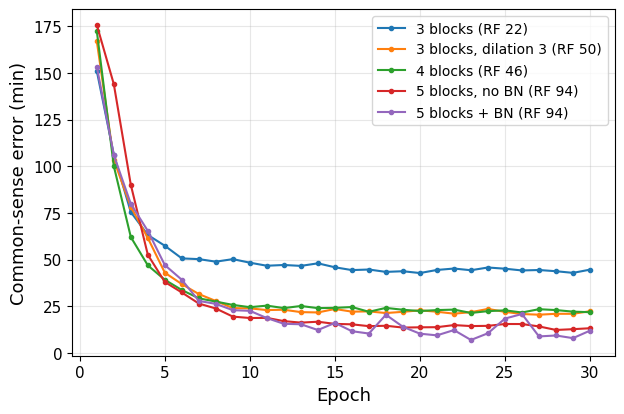

In [7]:
plt.rcParams.update({'font.size': 13, 'axes.labelsize': 13, 'legend.fontsize': 10,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11})

labels = {
    '3blocks_150':      '3 blocks (RF 22)',
    '3blocks_dil3_150': '3 blocks, dilation 3 (RF 50)',
    '4blocks_150':      '4 blocks (RF 46)',
    '5blocks_150':      '5 blocks, no BN (RF 94)',
    '5blocks_bn_150':   '5 blocks + BN (RF 94)',
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for r in results:
    if r['tag'] in labels:
        h = r['history']['val_cse']
        ax.plot(range(1, len(h) + 1), h, marker='o', ms=3, label=labels[r['tag']])
ax.set_xlabel('Epoch')
ax.set_ylabel('Common-sense error (min)')
ax.legend()
ax.grid(alpha=.3)
plt.savefig('fig_rf_ablation.pdf', bbox_inches='tight')
plt.show()

## 8. Save results

The models are dropped so the output is plain JSON.

In [8]:
out = [{k: v for k, v in r.items() if k != 'model'} for r in results]
with open(f'{DRIVE_DIR}/clock_rf_ablation.json', 'w') as f:
    json.dump(out, f, indent=2)
print('saved', len(out), 'runs')

saved 6 runs
